# Person 4 endpoint analysis

This notebook analyzes the four-parameter treatment sweep over κ_b, d_a, φ_max, and ξ. It focuses on the requested biological endpoints:

- community diversity
- time to steady state
- final resistant fraction
- resistant-cell clearance
- sensitive-cell survival and recovery
- peak population loss and bottleneck risk

The plots are designed to show both endpoint patterns and how parameter combinations affect the system.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style='whitegrid', context='notebook')
df = pd.read_csv('treatment_grid.csv')

PARAMS = ['kappa_b', 'd_a', 'phi_max', 'xi']
LABELS = {'kappa_b': 'κ_b', 'd_a': 'd_a', 'phi_max': 'φ_max', 'xi': 'ξ'}
OUTCOME_LABELS = {
    'diversity_final': 'Final Shannon diversity',
    't_steady_state': 'Time to steady state',
    'f_R_final': 'Final resistant fraction',
    't_recovery_S': 'Sensitive-cell recovery time',
    'peak_loss_total': 'Peak total-population loss',
    'peak_loss_S': 'Peak sensitive-population loss',
    'ns_final': 'Final sensitive density',
    'nr_final': 'Final resistant density'
}

df['total_final'] = df['ns_final'] + df['nr_final']
df['f_S_final'] = 1 - df['f_R_final']
df['community_ratio_R_to_S'] = df['nr_final'] / df['ns_final'].replace(0, np.nan)
df['steady_state_censored'] = ~df['ss_converged']

print('Rows:', len(df))
print('Nonconverged:', df['steady_state_censored'].sum())
display(df.head())

Rows: 194481
Nonconverged: 462


,kappa_b,d_a,phi_max,xi,f_R_final,resistant_eliminated,sensitive_survives,t_recovery_S,t_steady_state,ss_converged,peak_loss_S,peak_loss_total,diversity_final,diversity_min,ns_final,nr_final,total_final,f_S_final,community_ratio_R_to_S,steady_state_censored
0,0.0,0.0,0.0,0.00,0.224561,True,False,0.0,150.0,False,1.0,1.0,0.532621,0.532621,2.738129e-13,7.929425e-14,3.531072e-13,0.775439,0.289593,True
1,0.0,0.0,0.0,0.05,0.222397,True,False,0.0,150.0,False,1.0,1.0,0.529924,0.529924,2.079833e-13,5.948374e-14,2.674670e-13,0.777603,0.286002,True
2,0.0,0.0,0.0,0.10,0.220354,True,False,0.0,150.0,False,1.0,1.0,0.527356,0.527356,1.601825e-13,4.527304e-14,2.054555e-13,0.779646,0.282634,True
3,0.0,0.0,0.0,0.15,0.218425,True,False,0.0,150.0,False,1.0,1.0,0.524907,0.524907,1.249598e-13,3.492225e-14,1.598820e-13,0.781575,0.279468,True
4,0.0,0.0,0.0,0.20,0.216600,True,False,0.0,150.0,False,1.0,1.0,0.522570,0.522570,9.864908e-14,2.727514e-14,1.259242e-13,0.783400,0.276486,True


## 1. Basic endpoint distributions

These plots show the overall range of outcomes across the entire parameter sweep before examining individual parameter effects.

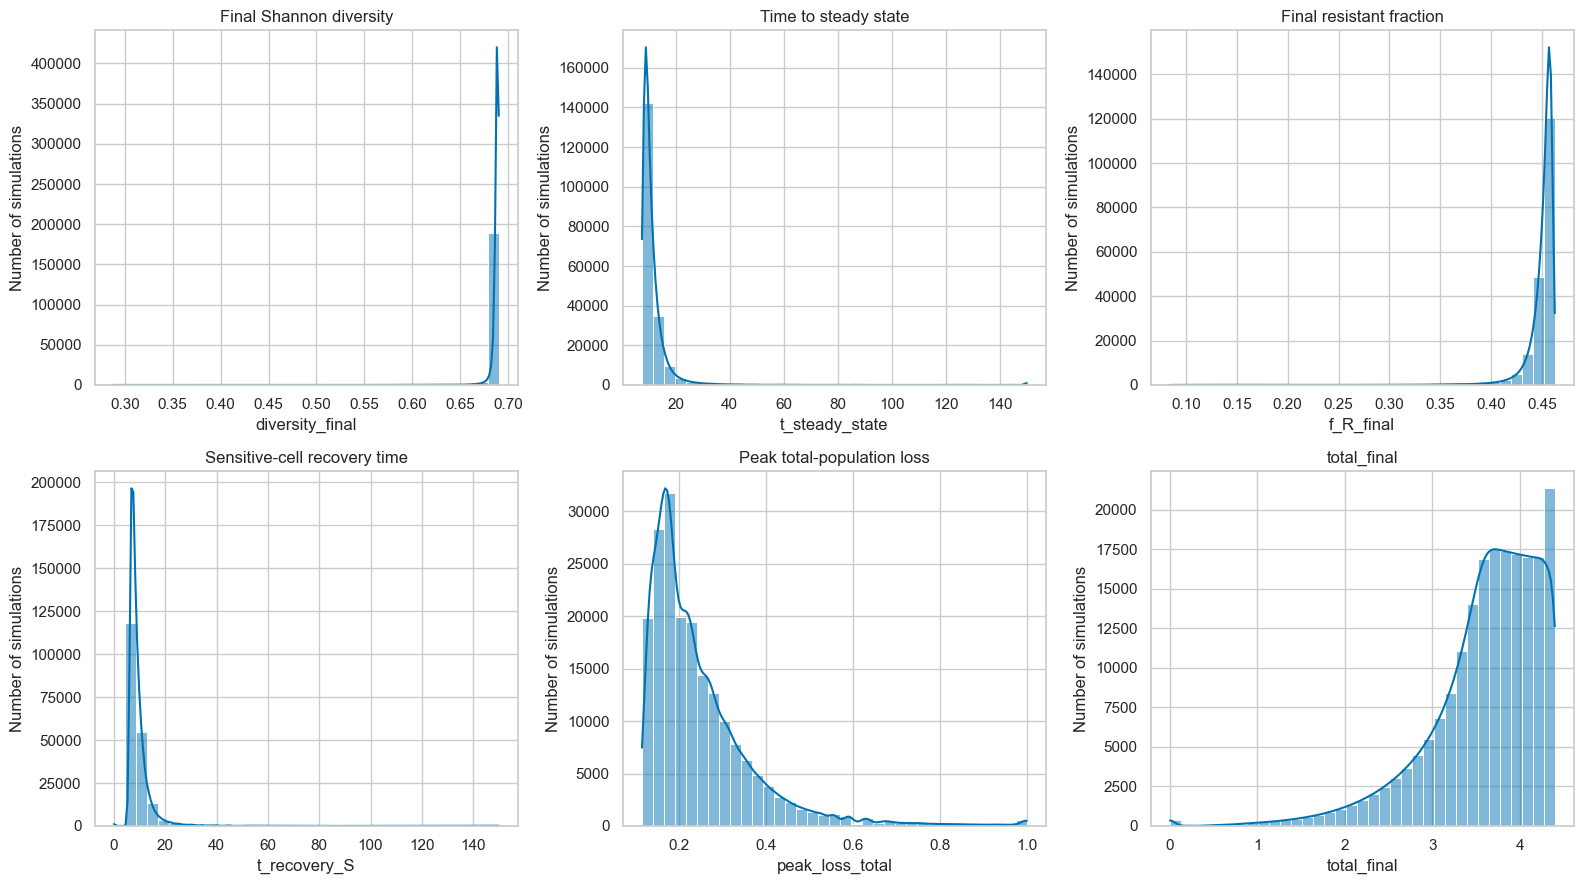

In [2]:
distribution_outcomes = [
    'diversity_final', 't_steady_state', 'f_R_final',
    't_recovery_S', 'peak_loss_total', 'total_final'
]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, outcome in zip(axes.flat, distribution_outcomes):
    sns.histplot(df[outcome], bins=35, kde=True, ax=ax, color='#0072B2')
    ax.set_title(OUTCOME_LABELS.get(outcome, outcome))
    ax.set_xlabel(outcome)
    ax.set_ylabel('Number of simulations')
plt.tight_layout()
plt.show()

## 2. Parameter-sweep heatmaps

Each heatmap varies two parameters on the axes and holds the other two at values closest to their model baselines. This is the most direct analogue of your teammate's α–c heatmaps.

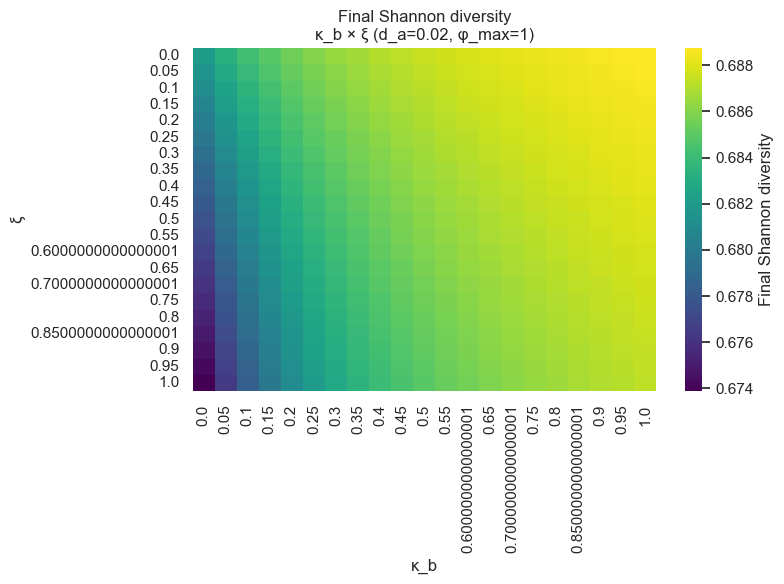

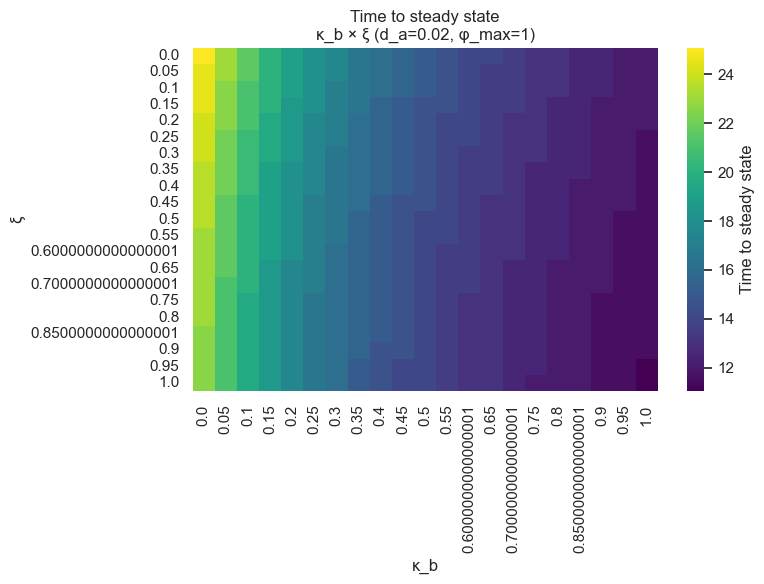

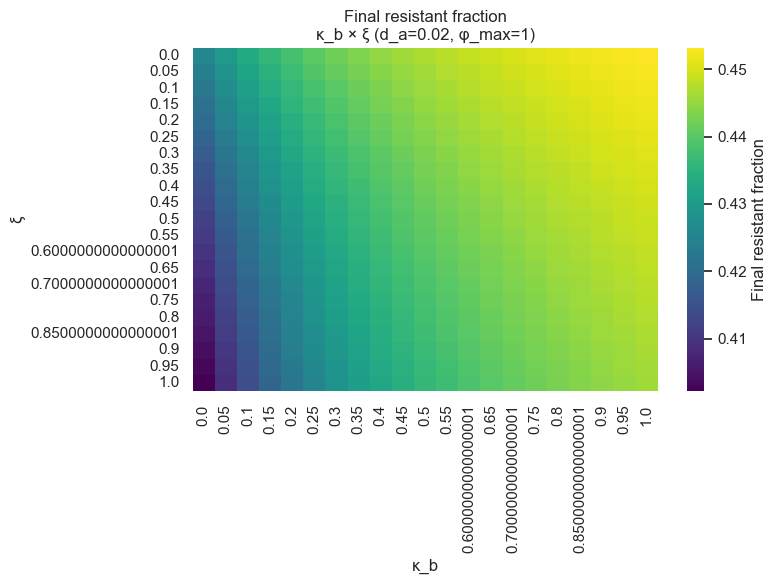

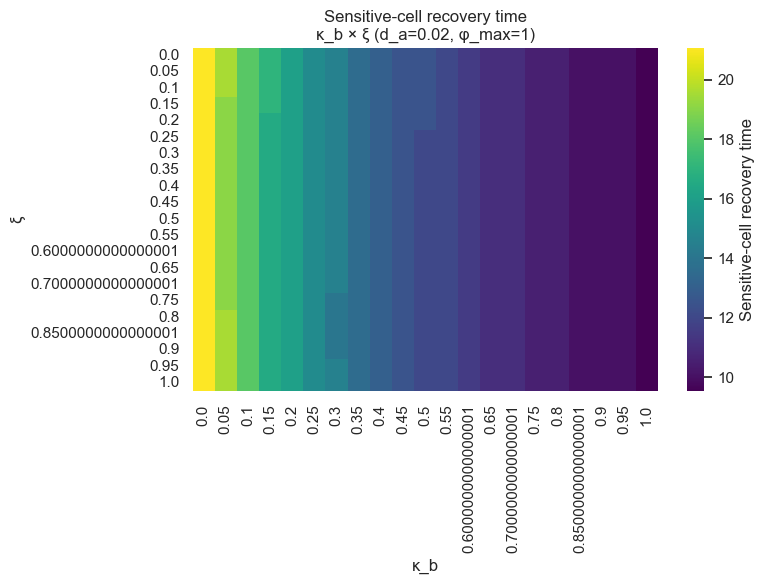

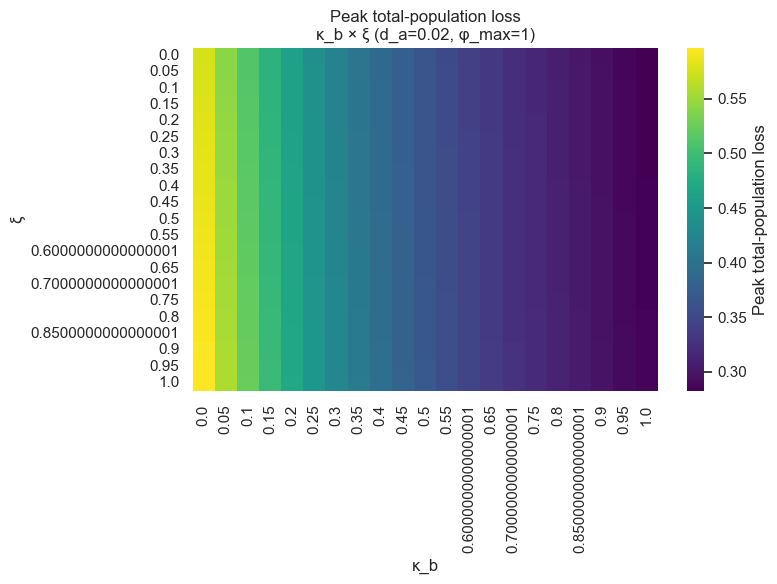

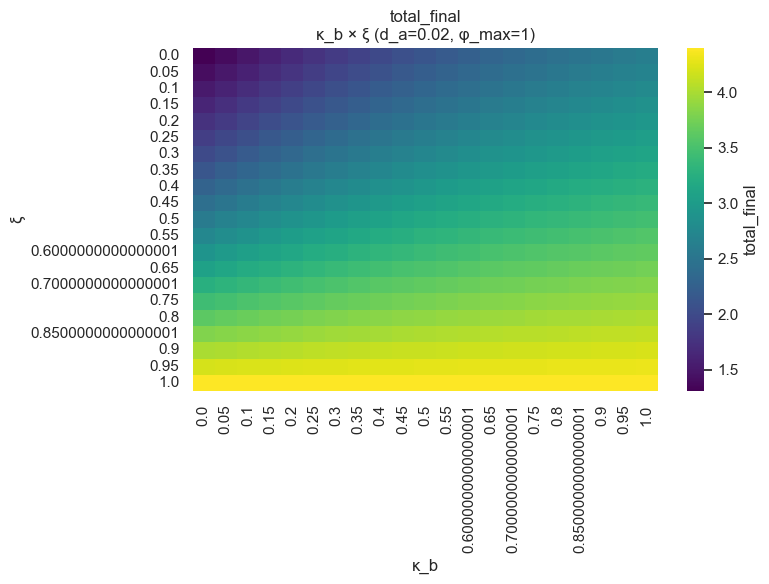

In [3]:
BASELINE = {'kappa_b': 0.35, 'd_a': 0.02, 'phi_max': 1.0, 'xi': 0.8}

def nearest_value(parameter, target=None):
    if target is None: target = BASELINE[parameter]
    values = np.asarray(df[parameter].unique())
    return values[np.argmin(np.abs(values - target))]

def sliced_table(outcome, x, y, fixed=None):
    fixed = fixed or {}
    sub = df.copy()
    used = {}
    for p in PARAMS:
        if p not in [x, y]:
            v = nearest_value(p, fixed.get(p))
            sub = sub[np.isclose(sub[p], v)]
            used[p] = v
    return sub.pivot(index=y, columns=x, values=outcome).sort_index(), used

def endpoint_heatmap(outcome, x='kappa_b', y='xi', fixed=None, cmap='viridis', center=None):
    table, used = sliced_table(outcome, x, y, fixed)
    fig, ax = plt.subplots(figsize=(8, 6))
    sns.heatmap(table, ax=ax, cmap=cmap, center=center, annot=False,
                cbar_kws={'label': OUTCOME_LABELS.get(outcome, outcome)})
    ax.set_xlabel(LABELS[x]); ax.set_ylabel(LABELS[y])
    suffix = ', '.join(f'{LABELS[p]}={v:g}' for p, v in used.items())
    ax.set_title(f'{OUTCOME_LABELS.get(outcome, outcome)}\n{LABELS[x]} × {LABELS[y]} ({suffix})')
    plt.tight_layout()
    return fig, ax

for outcome in ['diversity_final', 't_steady_state', 'f_R_final', 't_recovery_S', 'peak_loss_total', 'total_final']:
    endpoint_heatmap(outcome, x='kappa_b', y='xi')
    plt.show()

## 3. Compare all parameter pairs

This tests whether an apparent κ_b–ξ relationship is specific to one parameter pair or appears across other combinations.

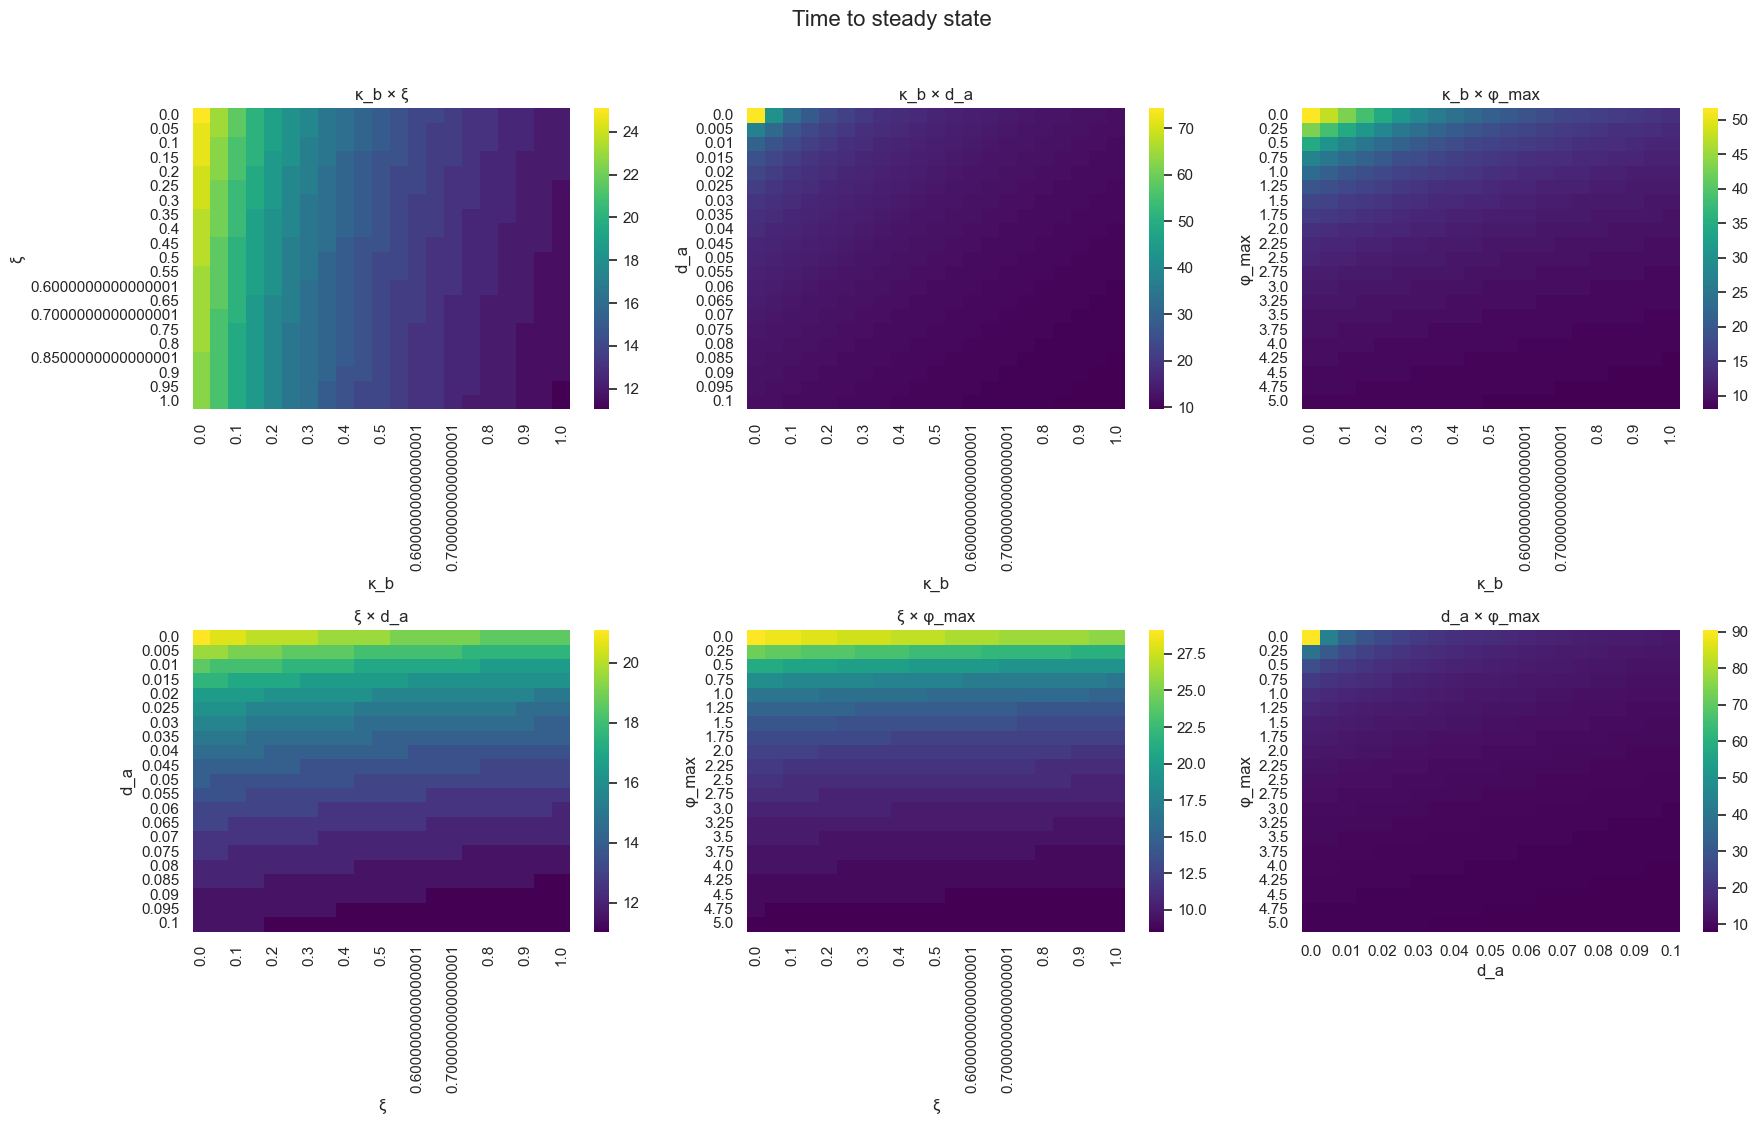

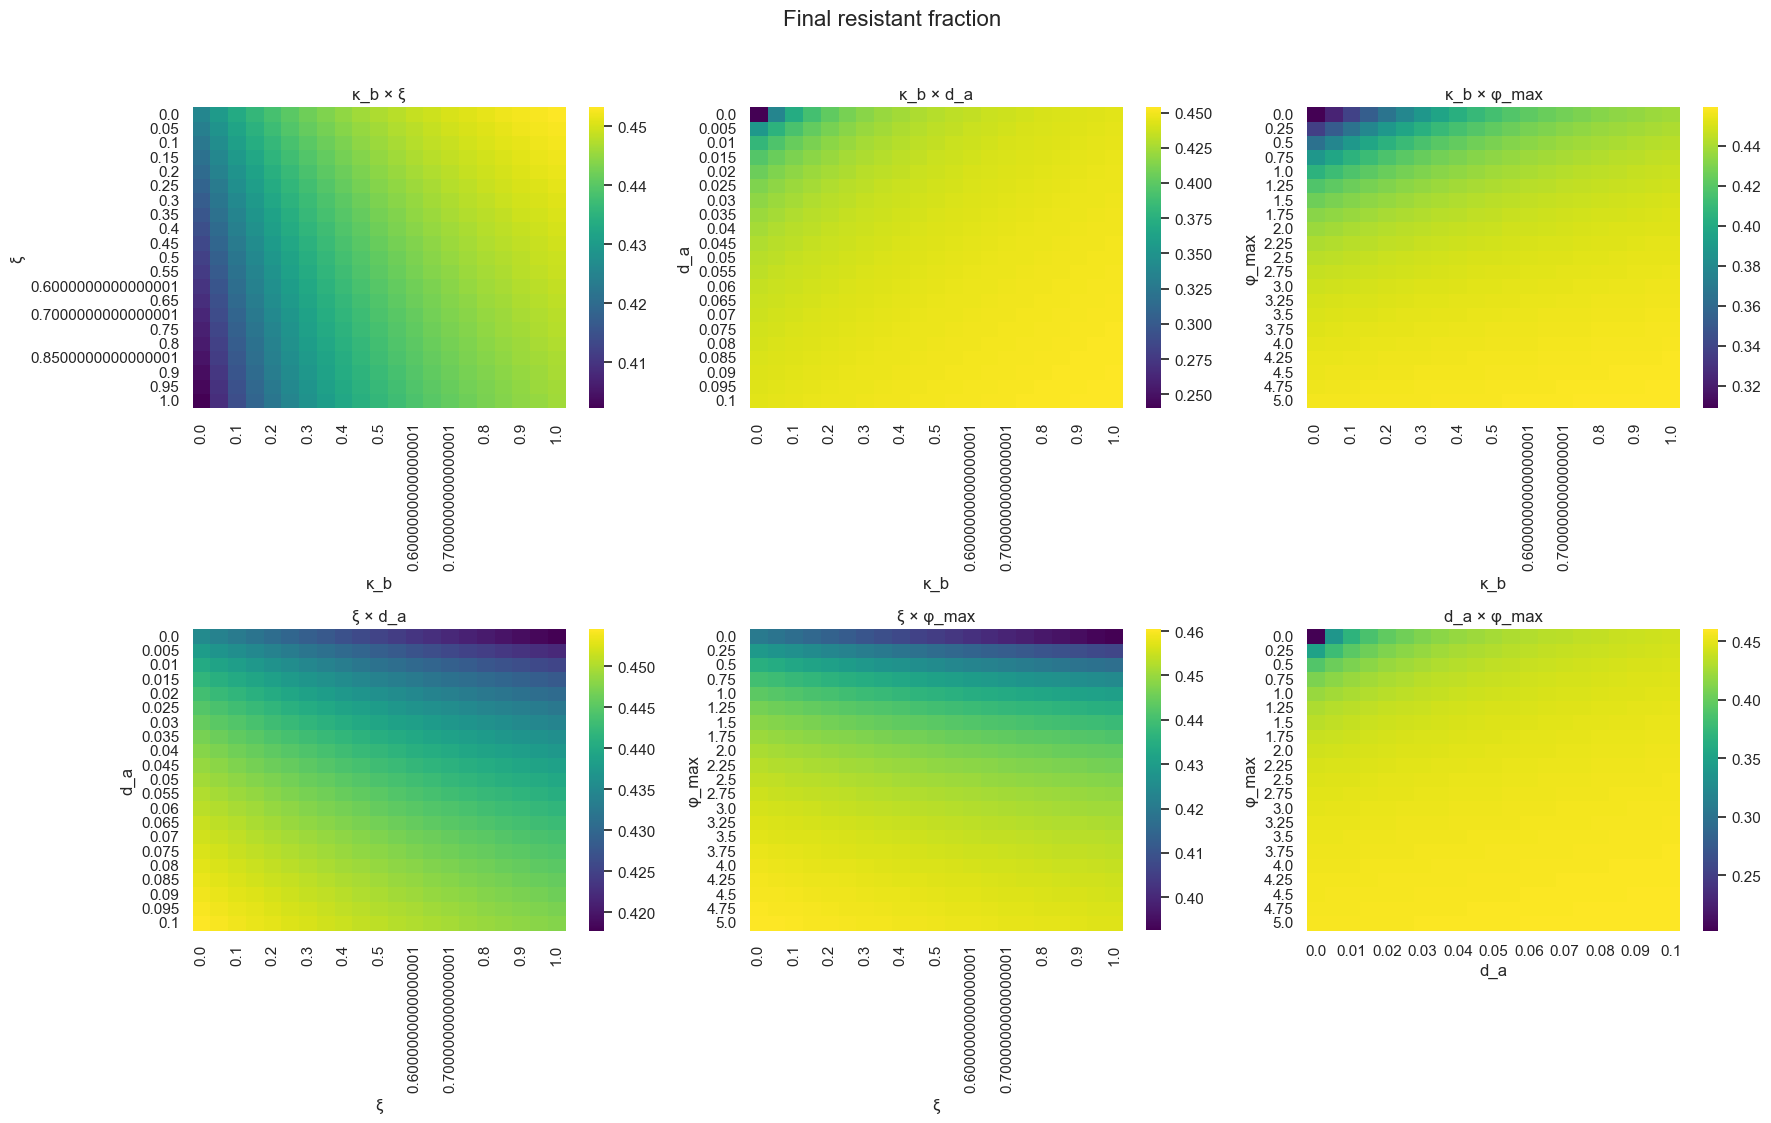

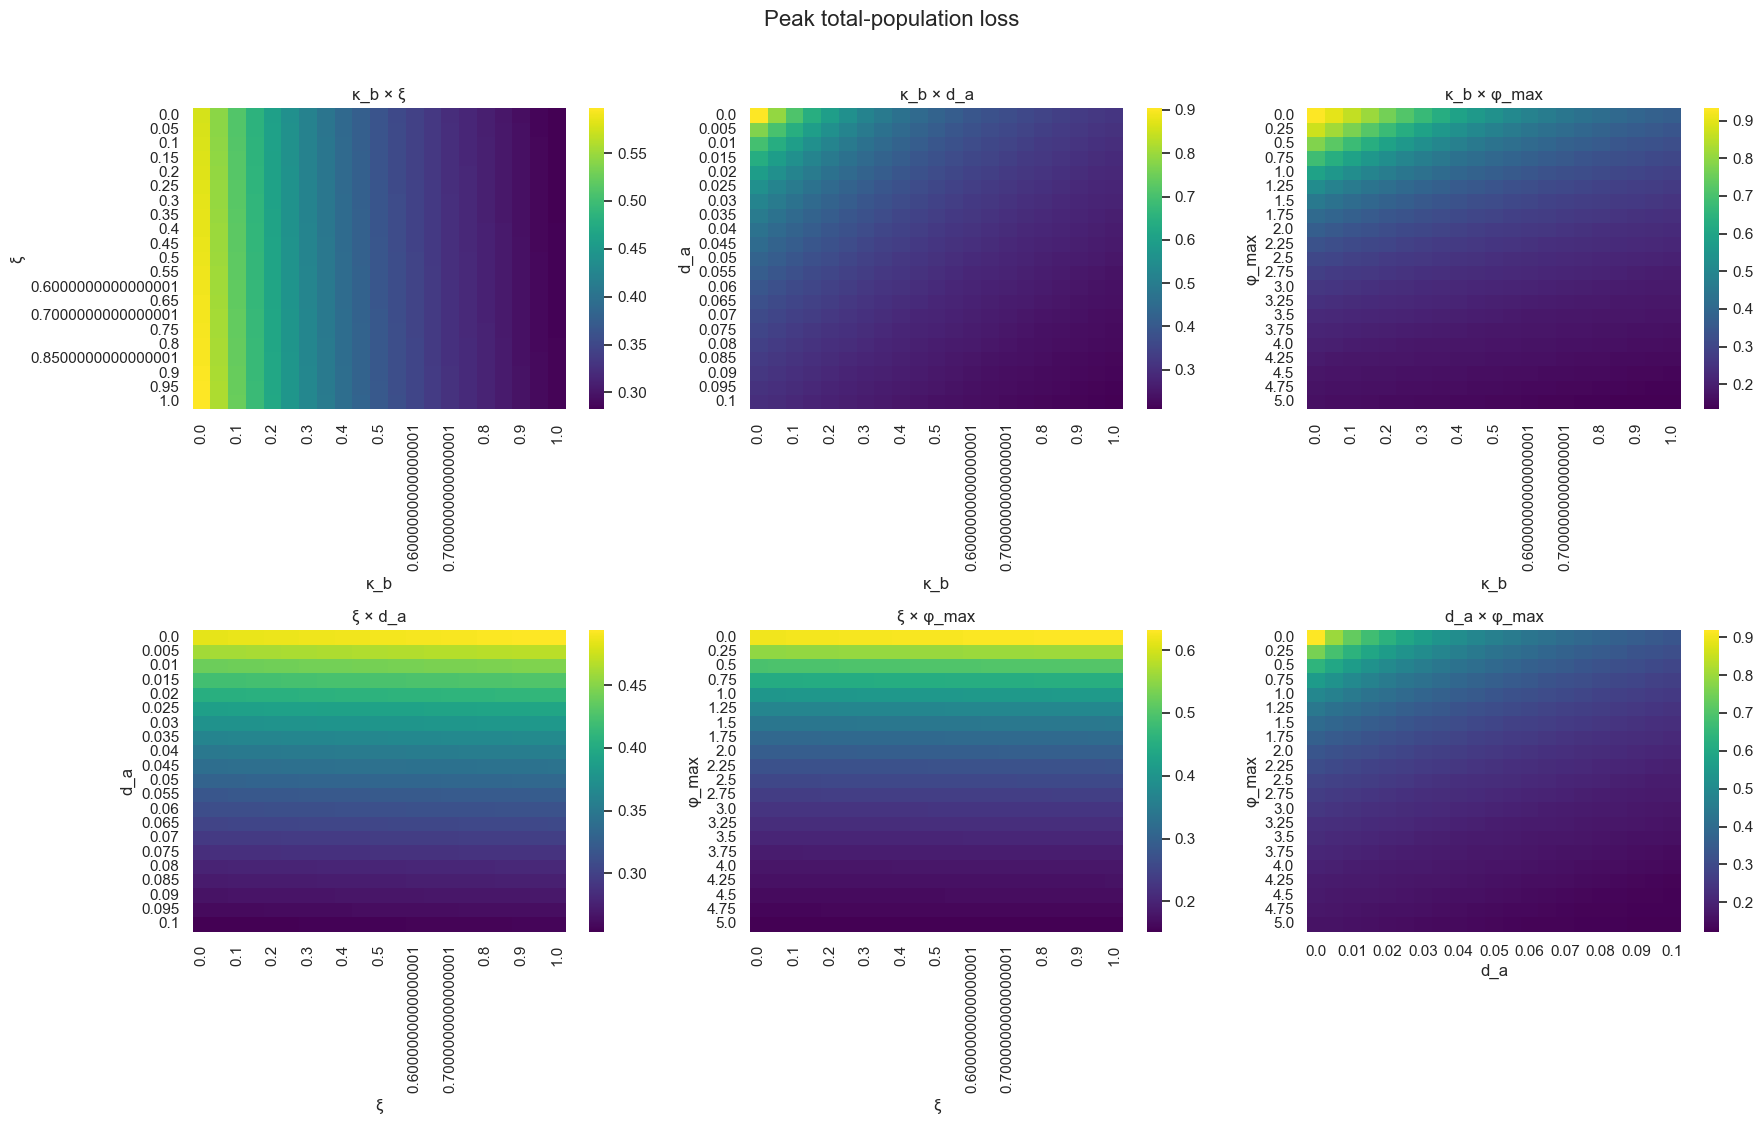

In [4]:
pairs = [('kappa_b', 'xi'), ('kappa_b', 'd_a'), ('kappa_b', 'phi_max'),
         ('xi', 'd_a'), ('xi', 'phi_max'), ('d_a', 'phi_max')]

def pair_grid(outcome):
    fig, axes = plt.subplots(2, 3, figsize=(18, 11))
    for ax, (x, y) in zip(axes.flat, pairs):
        table, used = sliced_table(outcome, x, y)
        sns.heatmap(table, ax=ax, cmap='viridis', cbar=True)
        ax.set_xlabel(LABELS[x]); ax.set_ylabel(LABELS[y])
        ax.set_title(f'{LABELS[x]} × {LABELS[y]}')
    fig.suptitle(OUTCOME_LABELS.get(outcome, outcome), fontsize=16, y=1.02)
    plt.tight_layout()
    return fig

pair_grid('t_steady_state')
plt.show()

pair_grid('f_R_final')
plt.show()

pair_grid('peak_loss_total')
plt.show()

## 4. Final community composition

The final resistant fraction should be interpreted together with total population size. A high resistant fraction can mean resistance dominates, but it can also occur because both populations are nearly extinct.

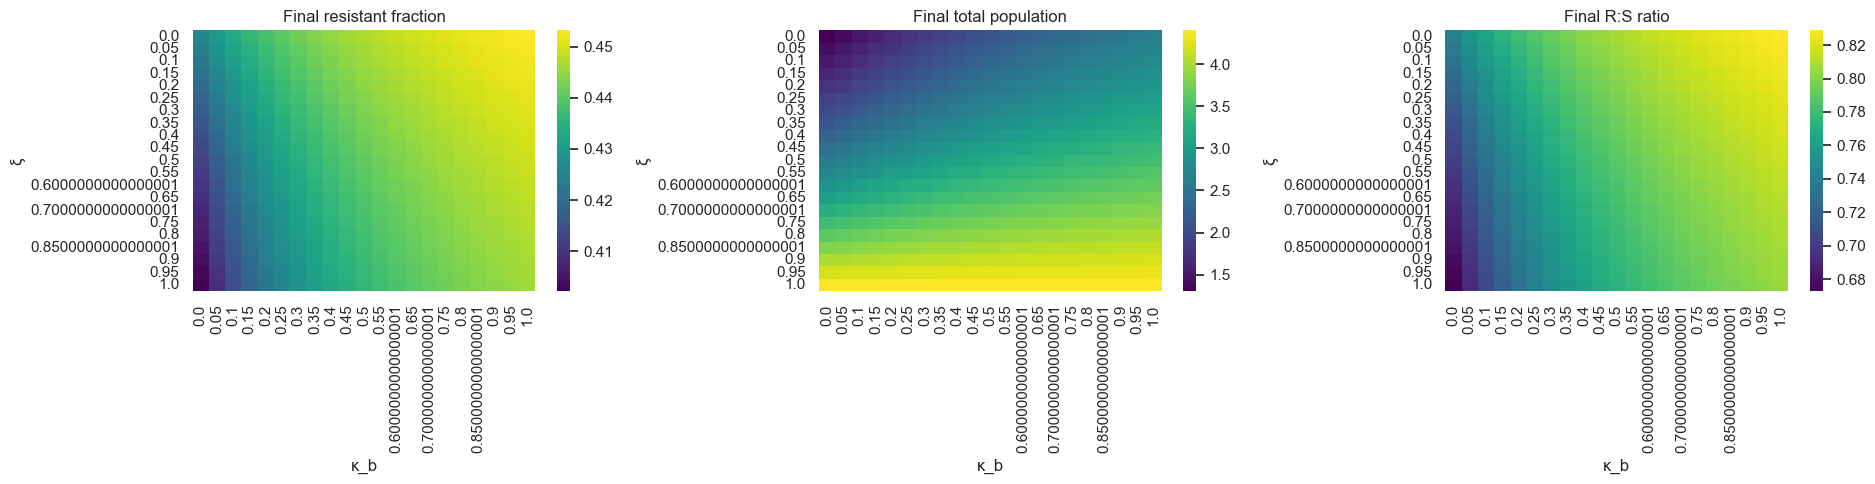

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5))
for ax, outcome, title in zip(axes, ['f_R_final', 'total_final', 'community_ratio_R_to_S'], ['Final resistant fraction', 'Final total population', 'Final R:S ratio']):
    table, used = sliced_table(outcome, 'kappa_b', 'xi')
    sns.heatmap(table, ax=ax, cmap='viridis', cbar=True)
    ax.set_xlabel('κ_b'); ax.set_ylabel('ξ'); ax.set_title(title)
plt.tight_layout()
plt.show()

## 5. Resistant clearance and sensitive survival

These are categorical biological outcomes, not just continuous endpoint values.

/var/folders/d7/rgjpwt31019czzdds44x_g3w0000gp/T/ipykernel_42782/3667259140.py:13: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  codes = pivot.replace({'S survives / R cleared': 0, 'S survives / R retained': 1, 'S not viable': 2, 'other': 3})


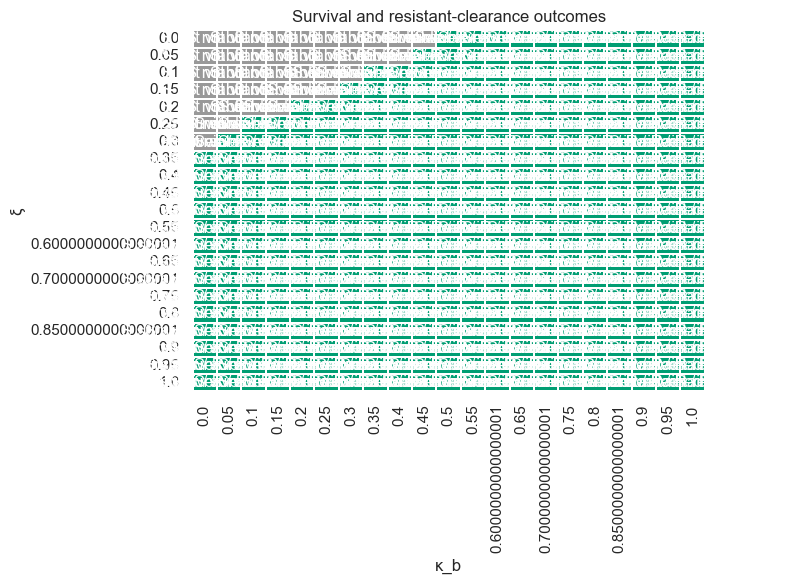

Sensitive survives: 0.9692874882379255
Resistant eliminated: 0.0017893778826723434
Both S survives and R cleared: 0.0


In [6]:
sub = df.copy()
for p in ['d_a', 'phi_max']:
    sub = sub[np.isclose(sub[p], nearest_value(p))]

sub['outcome_class'] = np.select(
    [sub['sensitive_survives'] & sub['resistant_eliminated'],
     sub['sensitive_survives'] & ~sub['resistant_eliminated'],
     ~sub['sensitive_survives']],
    ['S survives / R cleared', 'S survives / R retained', 'S not viable'],
    default='other'
)
pivot = sub.pivot(index='xi', columns='kappa_b', values='outcome_class')
codes = pivot.replace({'S survives / R cleared': 0, 'S survives / R retained': 1, 'S not viable': 2, 'other': 3})
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(codes, ax=ax, cmap=['#009E73', '#E69F00', '#D55E00', '#999999'], cbar=False, annot=pivot, fmt='', linewidths=.2)
ax.set_xlabel('κ_b'); ax.set_ylabel('ξ'); ax.set_title('Survival and resistant-clearance outcomes')
plt.tight_layout(); plt.show()

print('Sensitive survives:', df['sensitive_survives'].mean())
print('Resistant eliminated:', df['resistant_eliminated'].mean())
print('Both S survives and R cleared:', (df['sensitive_survives'] & df['resistant_eliminated']).mean())

## 6. Parameter effects on each endpoint

Spearman correlations capture monotonic effects even when the relationship is not perfectly linear. These are descriptive, not causal tests of parameter interaction.

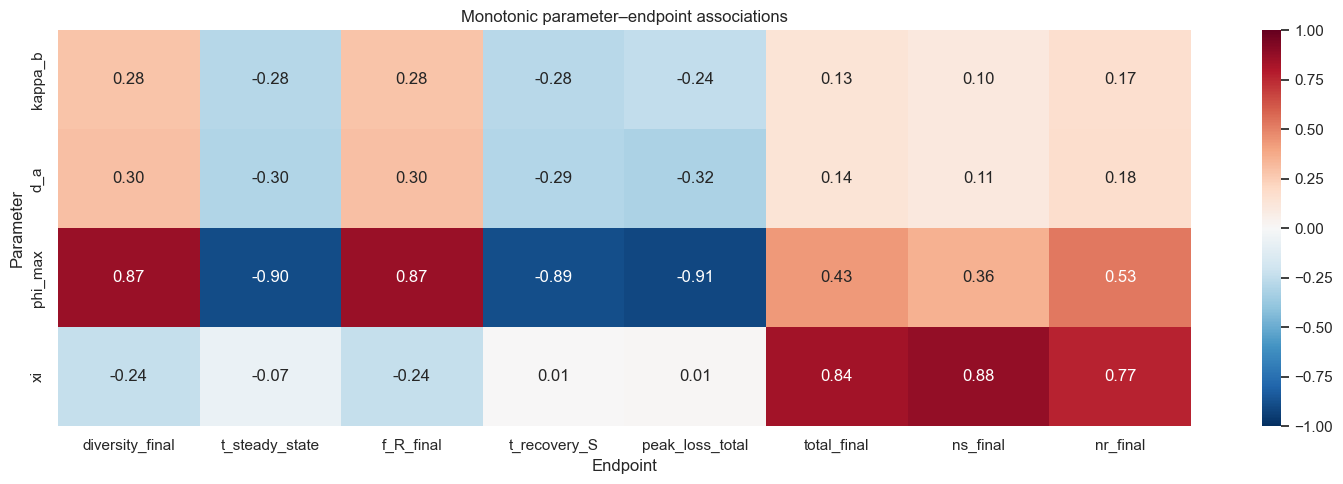

,diversity_final,t_steady_state,f_R_final,t_recovery_S,peak_loss_total,total_final,ns_final,nr_final
kappa_b,0.285,-0.284,0.285,-0.279,-0.244,0.134,0.102,0.170
d_a,0.303,-0.301,0.303,-0.294,-0.316,0.140,0.107,0.177
phi_max,0.865,-0.896,0.865,-0.887,-0.910,0.433,0.357,0.529
xi,-0.242,-0.067,-0.242,0.006,0.008,0.837,0.876,0.772


In [7]:
outcomes = ['diversity_final', 't_steady_state', 'f_R_final', 't_recovery_S', 'peak_loss_total', 'total_final', 'ns_final', 'nr_final']
corr = df[PARAMS + outcomes].corr(method='spearman').loc[PARAMS, outcomes]

plt.figure(figsize=(15, 5))
sns.heatmap(corr, annot=True, cmap='RdBu_r', center=0, vmin=-1, vmax=1, fmt='.2f')
plt.title('Monotonic parameter–endpoint associations')
plt.xlabel('Endpoint'); plt.ylabel('Parameter')
plt.tight_layout(); plt.show()
display(corr.round(3))

## 7. Nonconvergence and censoring

A simulation that does not meet the steady-state criterion by the end of the time window is not automatically permanently nonconvergent. Treat it as right-censored and inspect where those points occur.

Nonconverged simulations: 462


,kappa_b,d_a,phi_max,xi,t_steady_state,ns_final,nr_final,peak_loss_total
count,462.000000,462.000000,462.000000,462.000000,462.0,4.620000e+02,4.620000e+02,462.000000
mean,0.093182,0.000909,0.227273,0.500000,150.0,1.881491e-01,2.108069e-02,0.998327
std,0.085766,0.001931,0.249235,0.303093,0.0,5.998138e-01,6.365481e-02,0.006919
min,0.000000,0.000000,0.000000,0.000000,150.0,6.833792e-15,1.673925e-15,0.947106
25%,0.000000,0.000000,0.000000,0.250000,150.0,3.357936e-11,6.940257e-12,0.999928
50%,0.075000,0.000000,0.250000,0.500000,150.0,3.174389e-08,5.346758e-09,1.000000
75%,0.150000,0.000000,0.500000,0.750000,150.0,4.791124e-04,6.458724e-05,1.000000
max,0.300000,0.005000,0.750000,1.000000,150.0,4.027998e+00,4.080756e-01,1.000000


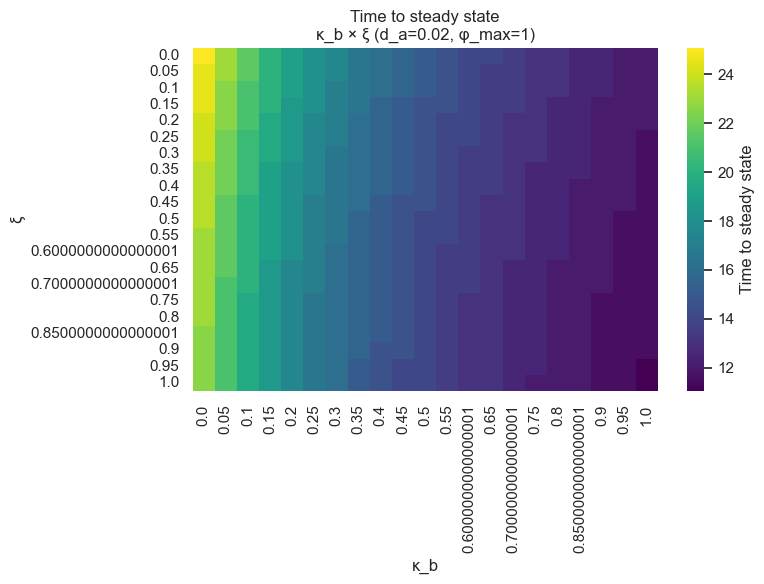

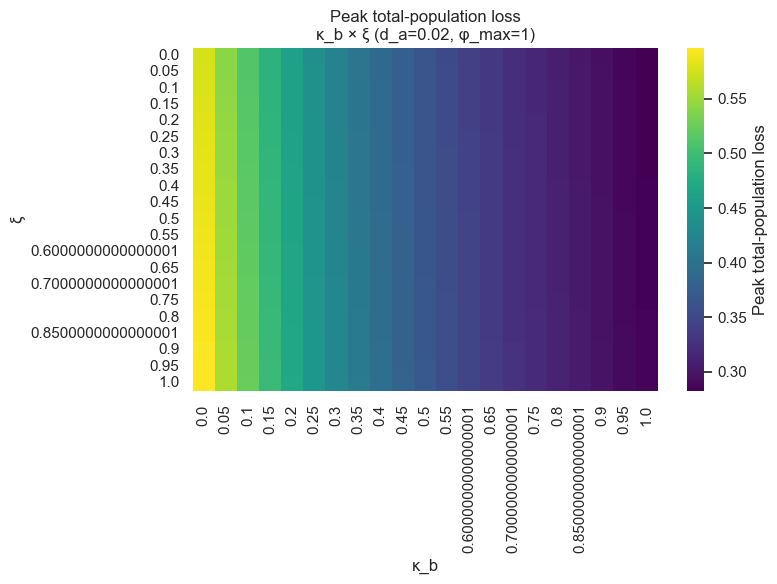

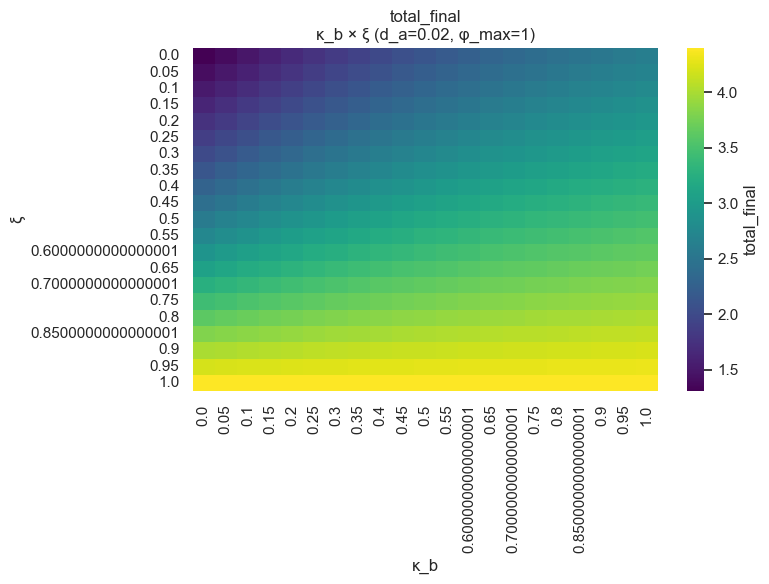

In [8]:
nonconv = df[~df['ss_converged']]
print('Nonconverged simulations:', len(nonconv))
display(nonconv[PARAMS + ['t_steady_state', 'ns_final', 'nr_final', 'peak_loss_total']].describe())

if len(nonconv):
    for outcome in ['t_steady_state', 'peak_loss_total', 'total_final']:
        endpoint_heatmap(outcome, x='kappa_b', y='xi')
        plt.show()

## Interpretation priorities

1. Use `peak_loss_total` to describe acute bottleneck severity.
2. Use `t_steady_state` and `t_recovery_S` to describe how quickly the community returns to stable behavior.
3. Use `f_R_final` together with `total_final`; never interpret resistant fraction alone.
4. Use `resistant_eliminated` and `sensitive_survives` for biologically meaningful categorical outcomes.
5. Use `ns_final` and `nr_final` to understand whether ξ primarily changes the recovered population size rather than the initial crash.